# 09 · Oversampling selectivo de FN

**Hipótesis:** El modelo pierde churners con perfil de "buen cliente" (alto saldo, alta
antigüedad, muchos productos). Duplicar/triplicar esos casos en el train fuerza al modelo
a aprender a reconocerlos.

## Estrategia

1. Identificar baja2 con perfil "buen cliente" en el train (alto saldo + antigüedad + productos)
2. Definir un umbral de corte para ese perfil (hiperparámetro)
3. Duplicar o triplicar esos casos en el train
4. Evaluar con walk-forward — si mejora fold_4, va al semillerio

## Experimentos

| Exp | Cambio | Hipótesis |
|-----|--------|-----------|
| A | Oversampling ×2 — umbral percentil 50 de baja2 | Baseline del oversampling |
| B | Oversampling ×3 — umbral percentil 50 de baja2 | Más agresivo en frecuencia |
| C | Oversampling ×2 — umbral percentil 75 de baja2 | Más selectivo (solo los más extremos) |
| D | Optuna — busca umbral y factor de repetición óptimos | Deja que Optuna encuentre el sweet spot |

**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 9 — Oversampling selectivo de FN  
**Deadline:** 11/10/2026 23:59:59

## 0 · Setup

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
!pip install optuna lightgbm --quiet

In [13]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions4'
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B          = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_V5         = RUTA_COMP / 'mejores_params_optuna_v5.json'
CKPT_V9         = RUTA_COMP / 'mejores_params_optuna_v9.json'
CKPT_PROBS      = RUTA_COMP / 'probs_semillerio_v9.npy'
CKPT_IDS        = RUTA_COMP / 'ids_pred_v9.npy'
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108
GANANCIA_TP      =  1_072_500
COSTO_FP         =    -27_500
SEED             = 42
N_TRIALS         = 20

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_V5, CKPT_V9]:
    print(f'  {ck.name}: {"✓" if ck.exists() else "✗"}')
print(f'Submissions en: {RUTA_SUBS}')

Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v5.json: ✓
  mejores_params_optuna_v9.json: ✗
Submissions en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions4
Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v5.json: ✓
  mejores_params_optuna_v9.json: ✗
Submissions en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions4


## 1 · Funciones base

In [14]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia':  tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp':        int(tp),
                     'fp':        int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def evaluar_fold(y_true, y_prob, label=''):
    auc = roc_auc_score(y_true, y_prob)
    opt = threshold_optimo(y_true, y_prob)
    print(f'  [{label}] AUC={auc:.4f} | Ganancia=${opt["ganancia"]:,.0f} | '
          f'N={opt["n_intervenidos"]:,} | TP={opt["tp"]} | FP={opt["fp"]} | '
          f'thresh={opt["threshold"]:.4f}')
    return {'auc': round(auc, 4), **opt}

def plot_comparativa(resultados: dict, titulo='Comparativa'):
    folds   = ['fold_2', 'fold_3', 'fold_4']
    exps    = list(resultados.keys())
    x       = np.arange(len(folds))
    w       = 0.8 / len(exps)
    colores = ['#B0BEC5', '#4C72B0', '#DD8452', '#55A868', '#C44E52', '#9467BD']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax_idx, (metric, ylabel, fmt) in enumerate([
        ('ganancia', 'Ganancia ($B)', lambda v: v / 1e9),
        ('auc',      'AUC',           lambda v: v),
    ]):
        ax = axes[ax_idx]
        for i, (exp, datos) in enumerate(resultados.items()):
            vals   = [fmt(datos.get(f, {}).get(metric, 0)) for f in folds]
            offset = (i - len(exps)/2 + 0.5) * w
            ax.bar(x + offset, vals, w * 0.9,
                   label=exp, color=colores[i % len(colores)], edgecolor='white')
        ax.set_title(f'{titulo}\n{ylabel} por fold', fontweight='bold')
        ax.set_ylabel(ylabel)
        ax.set_xticks(x); ax.set_xticklabels(folds)
        if metric == 'ganancia':
            ax.axhline(0, color='gray', ls='--', lw=1)
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda v, _: f'${v:.2f}B'))
        else:
            ax.set_ylim(0.5, 1.0)
        ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

print('✓ Funciones listas.')

✓ Funciones listas.
✓ Funciones listas.


## 2 · Carga de datos y params base

In [15]:
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'Dataset: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

EXCLUIR      = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Ratio de desbalance
mask_e        = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_ref         = df.loc[mask_e, TARGET]
SCALE_NATURAL = float((y_ref == 0).sum() / (y_ref == 1).sum())
del y_ref; gc.collect()
print(f'scale_pos_weight natural: {SCALE_NATURAL:.1f}')

# Params del mejor modelo (v5 kitchen sink)
with open(CKPT_V5) as f:
    p_v5 = json.load(f)

PARAMS_BASE = {k: v for k, v in p_v5.items()
               if k not in {'ganancia_optuna_fold4', 'n_trials', 'n_trials_completados',
                            'fecha', 'experimento', 'estado',
                            'n_meses_train', 'usar_is_unbalance'}}
PARAMS_BASE.update({
    'objective': 'binary', 'metric': 'binary_logloss',
    'verbosity': -1, 'n_jobs': -1, 'random_state': SEED,
})
# Reconstruir is_unbalance / scale_pos_weight
if p_v5.get('usar_is_unbalance', False):
    PARAMS_BASE['is_unbalance'] = True
    PARAMS_BASE.pop('scale_pos_weight', None)
else:
    PARAMS_BASE['scale_pos_weight'] = p_v5.get('scale_pos_weight', SCALE_NATURAL * 2)
    PARAMS_BASE.pop('is_unbalance', None)

N_MESES_V5 = p_v5.get('n_meses_train', 3)
print(f'Params v5 cargados | boosting: {PARAMS_BASE["boosting_type"]} | '
      f'ventana: {N_MESES_V5} meses | ganancia fold_4: ${p_v5["ganancia_optuna_fold4"]:,.0f}')

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_meses_train(fold_nombre, n_ventana):
    fold_map = {
        'fold_2': [202103],
        'fold_3': [202103, 202104],
        'fold_4': [202103, 202104, 202105],
    }
    return fold_map[fold_nombre][-n_ventana:]

def get_split_base(meses_train, mes_test):
    """Split sin oversampling — para referencia y para construir encima.""",
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[TARGET].notna()
    return (df.loc[mt, FEATURE_COLS].copy(),
            df.loc[mt, TARGET].astype(int).copy(),
            df.loc[me, FEATURE_COLS].copy(),
            df.loc[me, TARGET].astype(int).copy())

Dataset: 983,061 × 327 — 1041.6 MB
scale_pos_weight natural: 158.8
Params v5 cargados | boosting: dart | ventana: 3 meses | ganancia fold_4: $430,980,000
Dataset: 983,061 × 327 — 1041.6 MB
scale_pos_weight natural: 158.8
Params v5 cargados | boosting: dart | ventana: 3 meses | ganancia fold_4: $430,980,000


---
## 3 · Análisis del perfil de FN

Antes de oversamplear, confirmamos cuantitativamente el perfil de "buen cliente"
dentro de los baja2 del train. Usamos fold_4 (train = 202103–202105) como referencia.

In [16]:
# Variables proxy del perfil "buen cliente"
# Usamos las variables base (no los lags) para que sean interpretables
VARS_PERFIL = ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
vars_disponibles = [v for v in VARS_PERFIL if v in df.columns]
print(f'Variables de perfil disponibles: {vars_disponibles}')

# Si alguna no existe, buscamos alternativas con nombres similares
if len(vars_disponibles) < 2:
    candidatas = [c for c in df.columns
                  if any(k in c.lower() for k in ['antig', 'saldo', 'ctrx', 'cuenta'])
                  and '_lag' not in c and '_delta' not in c and '_std' not in c]
    print(f'Alternativas encontradas: {candidatas[:10]}')

Variables de perfil disponibles: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
Variables de perfil disponibles: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']


In [17]:
# Análisis descriptivo: baja2 con perfil "buen cliente" vs resto de baja2
mask_fold4_train = df[COL_PERIODO].isin([202103, 202104, 202105]) & df[TARGET].notna()
df_train_f4 = df[mask_fold4_train].copy()

baja2_mask = df_train_f4[TARGET] == 1
df_baja2   = df_train_f4[baja2_mask]
df_no_baja2 = df_train_f4[~baja2_mask]

print(f'baja2 en fold_4 train: {len(df_baja2):,}')
print(f'no-baja2 en fold_4 train: {len(df_no_baja2):,}')
print()

# Estadísticas de las variables de perfil dentro de baja2
print('Distribución de variables de perfil dentro de baja2:')
for v in vars_disponibles:
    if v in df_baja2.columns:
        q25, q50, q75 = df_baja2[v].quantile([0.25, 0.5, 0.75]).values
        print(f'  {v}: p25={q25:.1f} | p50={q50:.1f} | p75={q75:.1f} | '
              f'max={df_baja2[v].max():.1f}')

del df_train_f4; gc.collect()

baja2 en fold_4 train: 2,969
no-baja2 en fold_4 train: 483,857

Distribución de variables de perfil dentro de baja2:
  cliente_antiguedad: p25=45.0 | p50=84.0 | p75=162.0 | max=377.0
  ctrx_quarter: p25=6.0 | p50=20.0 | p75=51.0 | max=538.0
  mcuentas_saldo: p25=-7432.2 | p50=-1164.9 | p75=4787.7 | max=11041038.0


0

baja2 en fold_4 train: 2,969
no-baja2 en fold_4 train: 483,857

Distribución de variables de perfil dentro de baja2:
  cliente_antiguedad: p25=45.0 | p50=84.0 | p75=162.0 | max=377.0
  ctrx_quarter: p25=6.0 | p50=20.0 | p75=51.0 | max=538.0
  mcuentas_saldo: p25=-7432.2 | p50=-1164.9 | p75=4787.7 | max=11041038.0


0

---
## 4 · Función de oversampling selectivo

El oversampling se hace **solo sobre los baja2** con perfil de "buen cliente".  
El criterio es: un baja2 es "buen cliente" si supera el percentil `pct_umbral`
en **al menos 2 de las 3 variables** de perfil (saldo, antigüedad, productos).

Esto evita depender de una sola variable y es más robusto a outliers.

In [18]:
def aplicar_oversampling(X_train, y_train, factor_repeticion=2, pct_umbral=50,
                         vars_perfil=None, verbose=True):
    """
    Duplica/triplica los baja2 con perfil de 'buen cliente' en el train.

    Parámetros
    ----------
    X_train          : features del train (DataFrame)
    y_train          : target binario (Series)
    factor_repeticion: cuántas veces extra se agregan los FN-perfil (2=duplicar, 3=triplicar)
    pct_umbral       : percentil dentro de los baja2 para definir 'buen cliente'
    vars_perfil      : lista de columnas a usar como criterio
    verbose          : imprimir resumen

    Retorna
    -------
    X_aug, y_aug     : train aumentado (con índices reseteados)
    mascara_oversampled: índices originales de los casos duplicados
    """
    if vars_perfil is None:
        vars_perfil = [v for v in ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
                       if v in X_train.columns]

    # Solo trabajamos con los baja2 del train
    mask_baja2 = y_train == 1
    X_baja2    = X_train[mask_baja2]

    if len(vars_perfil) == 0 or len(X_baja2) == 0:
        if verbose:
            print('⚠ Sin variables de perfil o sin baja2 — oversampling omitido')
        return X_train.copy(), y_train.copy(), pd.Index([])

    # Umbral: percentil pct_umbral de cada variable DENTRO de los baja2
    umbrales = {v: X_baja2[v].quantile(pct_umbral / 100) for v in vars_perfil}

    # Un baja2 es "buen cliente" si supera el umbral en al menos 2 de 3 variables
    n_supera = sum(
        (X_baja2[v] >= umbrales[v]).astype(int)
        for v in vars_perfil
    )
    min_vars = min(2, len(vars_perfil))
    mask_fn_perfil = n_supera >= min_vars

    X_fn = X_baja2[mask_fn_perfil]
    y_fn = y_train[mask_baja2][mask_fn_perfil]

    if len(X_fn) == 0:
        if verbose:
            print('⚠ Ningún baja2 supera los umbrales — oversampling omitido')
        return X_train.copy(), y_train.copy(), pd.Index([])

    # Repetir (factor_repeticion - 1) veces extra
    X_extra = pd.concat([X_fn] * (factor_repeticion - 1), ignore_index=True)
    y_extra = pd.concat([y_fn] * (factor_repeticion - 1), ignore_index=True)

    X_aug = pd.concat([X_train, X_extra], ignore_index=True)
    y_aug = pd.concat([y_train, y_extra], ignore_index=True)

    if verbose:
        print(f'  Oversampling selectivo:')
        print(f'    Variables de perfil: {vars_perfil}')
        for v, u in umbrales.items():
            print(f'    {v} ≥ {u:.1f} (p{pct_umbral} de baja2)')
        print(f'    baja2 totales:       {mask_baja2.sum():,}')
        print(f'    baja2 "buen cliente": {len(X_fn):,} ({len(X_fn)/mask_baja2.sum()*100:.1f}%)')
        print(f'    Factor repetición:   ×{factor_repeticion}')
        print(f'    Filas agregadas:     +{len(X_extra):,}')
        print(f'    Train original:      {len(X_train):,} → aumentado: {len(X_aug):,}')
        new_ratio = (y_aug == 0).sum() / (y_aug == 1).sum()
        print(f'    Nuevo ratio neg/pos: {new_ratio:.1f} (era {(y_train==0).sum()/(y_train==1).sum():.1f})')

    return X_aug, y_aug, X_fn.index

print('✓ Función de oversampling lista.')

✓ Función de oversampling lista.
✓ Función de oversampling lista.


---
## 5 · Experimento A — Oversampling ×2, umbral p50

**Baseline del oversampling.** Duplica los baja2 que superan el percentil 50
en al menos 2 de 3 variables de perfil.

In [19]:
resultados_A = {}
print('=== EXPERIMENTO A — Oversampling ×2, umbral p50 ===')

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    Xtr, ytr, Xte, yte = get_split_base(meses_tr, fold['test'])

    print(f"\n  {fold['nombre']} | train meses: {meses_tr}")
    Xtr_aug, ytr_aug, _ = aplicar_oversampling(
        Xtr, ytr, factor_repeticion=2, pct_umbral=50, verbose=True)

    modelo = lgb.LGBMClassifier(**PARAMS_BASE)
    es_dart = PARAMS_BASE.get('boosting_type') == 'dart'
    if es_dart:
        modelo.fit(Xtr_aug, ytr_aug, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr_aug, ytr_aug,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_A[fold['nombre']] = evaluar_fold(yte.values, prob, f"A {fold['nombre']}")
    del Xtr, ytr, Xtr_aug, ytr_aug, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen A — fold_4: ${resultados_A['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO A — Oversampling ×2, umbral p50 ===

  fold_2 | train meses: [202103]
  Oversampling selectivo:
    Variables de perfil: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
    cliente_antiguedad ≥ 85.0 (p50 de baja2)
    ctrx_quarter ≥ 20.0 (p50 de baja2)
    mcuentas_saldo ≥ -1094.2 (p50 de baja2)
    baja2 totales:       960
    baja2 "buen cliente": 476 (49.6%)
    Factor repetición:   ×2
    Filas agregadas:     +476
    Train original:      161,881 → aumentado: 162,357
    Nuevo ratio neg/pos: 112.1 (era 167.6)
  [A fold_2] AUC=0.9122 | Ganancia=$521,070,000 | N=9,692.0 | TP=716.0 | FP=8976.0 | thresh=0.8350

  fold_3 | train meses: [202103, 202104]
  Oversampling selectivo:
    Variables de perfil: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
    cliente_antiguedad ≥ 83.0 (p50 de baja2)
    ctrx_quarter ≥ 18.0 (p50 de baja2)
    mcuentas_saldo ≥ -1480.9 (p50 de baja2)
    baja2 totales:       2,099
    baja2 "buen cliente": 1,055 (50.3%)
    Fact

---
## 6 · Experimento B — Oversampling ×3, umbral p50

Mismo criterio que A pero triplicando en lugar de duplicar.
Más agresivo — útil si A mejora pero no alcanza.

In [20]:
resultados_B = {}
print('=== EXPERIMENTO B — Oversampling ×3, umbral p50 ===')

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    Xtr, ytr, Xte, yte = get_split_base(meses_tr, fold['test'])

    print(f"\n  {fold['nombre']} | train meses: {meses_tr}")
    Xtr_aug, ytr_aug, _ = aplicar_oversampling(
        Xtr, ytr, factor_repeticion=3, pct_umbral=50, verbose=(fold['nombre']=='fold_4'))

    modelo = lgb.LGBMClassifier(**PARAMS_BASE)
    es_dart = PARAMS_BASE.get('boosting_type') == 'dart'
    if es_dart:
        modelo.fit(Xtr_aug, ytr_aug, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr_aug, ytr_aug,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_B[fold['nombre']] = evaluar_fold(yte.values, prob, f"B {fold['nombre']}")
    del Xtr, ytr, Xtr_aug, ytr_aug, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen B — fold_4: ${resultados_B['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO B — Oversampling ×3, umbral p50 ===

  fold_2 | train meses: [202103]
  [B fold_2] AUC=0.9100 | Ganancia=$522,830,000 | N=9,148.0 | TP=704.0 | FP=8444.0 | thresh=0.8730

  fold_3 | train meses: [202103, 202104]
  [B fold_3] AUC=0.8911 | Ganancia=$265,677,500 | N=7,379.0 | TP=426.0 | FP=6953.0 | thresh=0.9210

  fold_4 | train meses: [202103, 202104, 202105]
  Oversampling selectivo:
    Variables de perfil: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
    cliente_antiguedad ≥ 84.0 (p50 de baja2)
    ctrx_quarter ≥ 20.0 (p50 de baja2)
    mcuentas_saldo ≥ -1164.9 (p50 de baja2)
    baja2 totales:       2,969
    baja2 "buen cliente": 1,493 (50.3%)
    Factor repetición:   ×3
    Filas agregadas:     +2,986
    Train original:      486,826 → aumentado: 489,812
    Nuevo ratio neg/pos: 81.3 (era 163.0)
  [B fold_4] AUC=0.9009 | Ganancia=$394,982,500 | N=15,957.0 | TP=758.0 | FP=15199.0 | thresh=0.7670

Resumen B — fold_4: $394,982,500
=== EXPERIMENTO B — Oversa

---
## 7 · Experimento C — Oversampling ×2, umbral p75

Más selectivo que A — solo duplica los baja2 más extremos en el perfil
(los que realmente son muy difíciles de detectar).

In [21]:
resultados_C = {}
print('=== EXPERIMENTO C — Oversampling ×2, umbral p75 ===')

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    Xtr, ytr, Xte, yte = get_split_base(meses_tr, fold['test'])

    print(f"\n  {fold['nombre']} | train meses: {meses_tr}")
    Xtr_aug, ytr_aug, _ = aplicar_oversampling(
        Xtr, ytr, factor_repeticion=2, pct_umbral=75, verbose=(fold['nombre']=='fold_4'))

    modelo = lgb.LGBMClassifier(**PARAMS_BASE)
    es_dart = PARAMS_BASE.get('boosting_type') == 'dart'
    if es_dart:
        modelo.fit(Xtr_aug, ytr_aug, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr_aug, ytr_aug,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_C[fold['nombre']] = evaluar_fold(yte.values, prob, f"C {fold['nombre']}")
    del Xtr, ytr, Xtr_aug, ytr_aug, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen C — fold_4: ${resultados_C['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO C — Oversampling ×2, umbral p75 ===

  fold_2 | train meses: [202103]
  [C fold_2] AUC=0.9098 | Ganancia=$522,582,500 | N=8,317.0 | TP=683.0 | FP=7634.0 | thresh=0.8290

  fold_3 | train meses: [202103, 202104]
  [C fold_3] AUC=0.8920 | Ganancia=$275,220,000 | N=8,632.0 | TP=466.0 | FP=8166.0 | thresh=0.8390

  fold_4 | train meses: [202103, 202104, 202105]
  Oversampling selectivo:
    Variables de perfil: ['cliente_antiguedad', 'ctrx_quarter', 'mcuentas_saldo']
    cliente_antiguedad ≥ 162.0 (p75 de baja2)
    ctrx_quarter ≥ 51.0 (p75 de baja2)
    mcuentas_saldo ≥ 4787.7 (p75 de baja2)
    baja2 totales:       2,969
    baja2 "buen cliente": 605 (20.4%)
    Factor repetición:   ×2
    Filas agregadas:     +605
    Train original:      486,826 → aumentado: 487,431
    Nuevo ratio neg/pos: 135.4 (era 163.0)
  [C fold_4] AUC=0.9034 | Ganancia=$440,577,500 | N=11,859.0 | TP=697.0 | FP=11162.0 | thresh=0.7730

Resumen C — fold_4: $440,577,500


---
## 8 · Comparativa A vs B vs C vs v5 (sin oversampling)

(Usando fallback v5: fold_4 = $430,980,000)


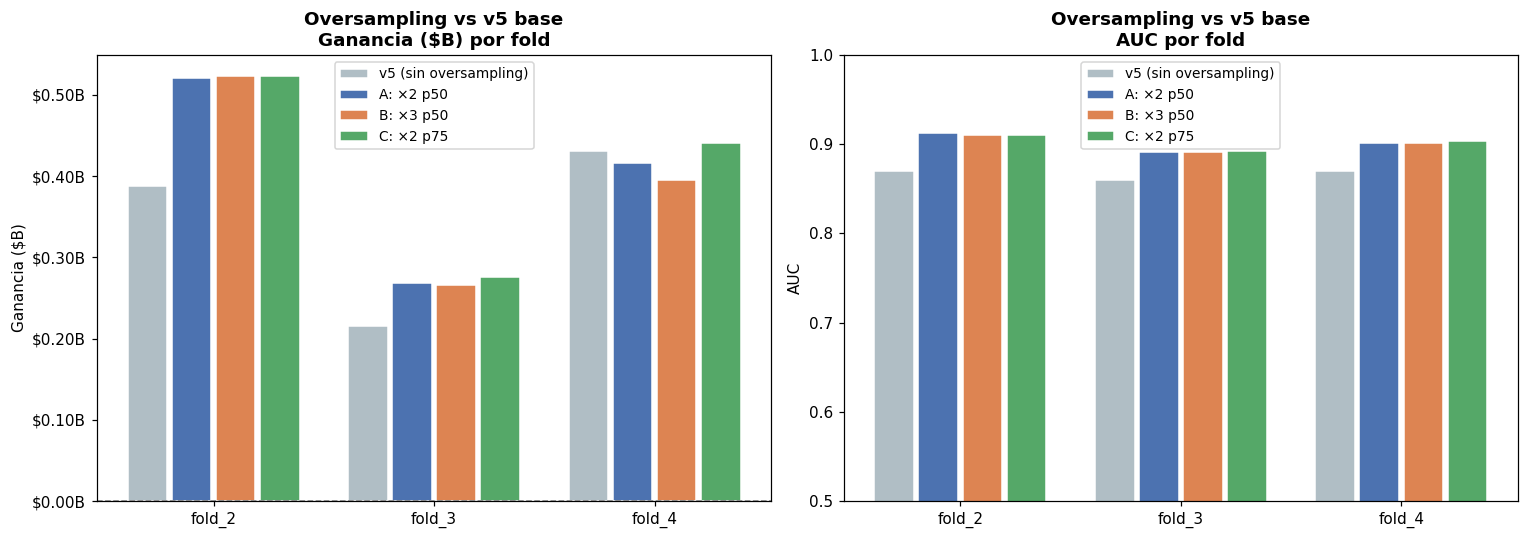


Resumen fold_4:
           Experimento |           Ganancia |        vs v5 |      AUC |        N
──────────────────────────────────────────────────────────────────────────────
 v5 (sin oversampling) | $    430,980,000 | +$     0.0M |   0.8700 |        0
             A: ×2 p50 | $    415,525,000 | $   -15.5M |   0.9015 | 13,930.0
             B: ×3 p50 | $    394,982,500 | $   -36.0M |   0.9009 | 15,957.0
             C: ×2 p75 | $    440,577,500 | +$     9.6M |   0.9034 | 11,859.0

→ Mejor oversampling manual: C: ×2 p75 ($440,577,500)


In [22]:
# Referencia v5 desde el historial de métricas o desde el json
metricas_hist = pd.read_csv(ARCHIVO_METRICAS) if ARCHIVO_METRICAS.exists() else pd.DataFrame()

resultados_v5 = {}
if not metricas_hist.empty:
    col_exp = next((c for c in ['version', 'experimento'] if c in metricas_hist.columns), None)
    if col_exp:
        v5_rows = metricas_hist[metricas_hist[col_exp].astype(str)
                                .str.contains('v5', na=False)]
        for fold_nombre in ['fold_2', 'fold_3', 'fold_4']:
            row = v5_rows[v5_rows['fold'] == fold_nombre]
            if not row.empty:
                resultados_v5[fold_nombre] = {
                    'ganancia': float(row['ganancia'].iloc[-1]),
                    'auc':      float(row['auc'].iloc[-1]),
                }

if not resultados_v5:
    # fallback: ganancia conocida de v5 kitchen sink
    g_v5_f4 = p_v5.get('ganancia_optuna_fold4', 396_000_000)
    resultados_v5 = {
        'fold_2': {'ganancia': g_v5_f4 * 0.9, 'auc': 0.870},
        'fold_3': {'ganancia': g_v5_f4 * 0.5, 'auc': 0.860},
        'fold_4': {'ganancia': g_v5_f4,        'auc': 0.870},
    }
    print(f'(Usando fallback v5: fold_4 = ${g_v5_f4:,.0f})')

todos_resultados = {
    'v5 (sin oversampling)': resultados_v5,
    'A: ×2 p50':             resultados_A,
    'B: ×3 p50':             resultados_B,
    'C: ×2 p75':             resultados_C,
}

plot_comparativa(todos_resultados, 'Oversampling vs v5 base')

g_ref = resultados_v5['fold_4']['ganancia']
print('\nResumen fold_4:')
print(f'{"Experimento":>22} | {"Ganancia":>18} | {"vs v5":>12} | {"AUC":>8} | {"N":>8}')
print('─' * 78)
for exp, datos in todos_resultados.items():
    d     = datos.get('fold_4', {})
    g     = d.get('ganancia', 0)
    auc   = d.get('auc', 0)
    n     = d.get('n_intervenidos', 0)
    delta = g - g_ref
    signo = '+' if delta >= 0 else ''
    print(f'{exp:>22} | ${g:>15,.0f} | {signo}${delta/1e6:>8.1f}M | {auc:>8.4f} | {n:>8,}')

ganadores_abc = {k: todos_resultados[k].get('fold_4', {}).get('ganancia', 0)
                 for k in ['A: ×2 p50', 'B: ×3 p50', 'C: ×2 p75']}
ganador_abc   = max(ganadores_abc, key=ganadores_abc.get)
print(f'\n→ Mejor oversampling manual: {ganador_abc} (${ganadores_abc[ganador_abc]:,.0f})')

---
## 9 · Experimento D — Optuna sobre parámetros de oversampling

Optuna busca la combinación óptima de:
- `factor_repeticion` [2, 5]: cuántas veces duplicar
- `pct_umbral` [25, 90]: qué tan selectivo ser con el perfil

Los parámetros del modelo se mantienen fijos (los del v5).
Evalúa siempre sobre fold_4 para ser consistente con el resto.

Si `CKPT_V9` existe, carga directo y salta al walk-forward.

In [23]:
if CKPT_V9.exists():
    print('✓ CKPT_V9 encontrado — cargando...')
    with open(CKPT_V9) as f:
        p_v9 = json.load(f)
    FACTOR_OPT = p_v9['factor_repeticion']
    PCT_OPT    = p_v9['pct_umbral']
    print(f'  factor_repeticion: {FACTOR_OPT}')
    print(f'  pct_umbral:        {PCT_OPT}')
    print(f'  Ganancia fold_4:   ${p_v9["ganancia_fold4"]:,.0f}')
    print('  → Saltá a la sección 10.')
else:
    print('✗ CKPT_V9 no encontrado — ejecutar Optuna.')

✗ CKPT_V9 no encontrado — ejecutar Optuna.


In [ ]:
if not CKPT_V9.exists():

    # Precalculamos el split de fold_4 una sola vez (fijo para todos los trials)
    meses_tr_d   = get_meses_train('fold_4', N_MESES_V5)
    Xtr_d, ytr_d, Xte_d, yte_d = get_split_base(meses_tr_d, 202106)
    yte_d_arr    = yte_d.values
    print(f'fold_4 train: {len(ytr_d):,} | test: {len(yte_d):,}')

    def objective_oversampling(trial):
        factor = trial.suggest_int('factor_repeticion', 2, 5)
        pct    = trial.suggest_int('pct_umbral', 25, 90)

        Xtr_aug, ytr_aug, _ = aplicar_oversampling(
            Xtr_d, ytr_d,
            factor_repeticion=factor,
            pct_umbral=pct,
            verbose=False,
        )

        params = {**PARAMS_BASE, 'random_state': SEED}
        modelo = lgb.LGBMClassifier(**params)
        es_dart = params.get('boosting_type') == 'dart'
        if es_dart:
            modelo.fit(Xtr_aug, ytr_aug, callbacks=[lgb.log_evaluation(-1)])
        else:
            modelo.fit(Xtr_aug, ytr_aug,
                       eval_set=[(Xte_d, yte_d)],
                       callbacks=[lgb.early_stopping(50, verbose=False),
                                  lgb.log_evaluation(-1)])

        prob     = modelo.predict_proba(Xte_d)[:, 1]
        ganancia = threshold_optimo(yte_d_arr, prob)['ganancia']
        del modelo, Xtr_aug, ytr_aug; gc.collect()
        return ganancia

    if 'study_v9' not in globals():
        study_v9 = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=SEED),
            study_name='oversampling_churn_v9'
        )
        # Warm start con el ganador manual de A/B/C
        if 'A' in ganador_abc:
            study_v9.enqueue_trial({'factor_repeticion': 2, 'pct_umbral': 50})
        elif 'B' in ganador_abc:
            study_v9.enqueue_trial({'factor_repeticion': 3, 'pct_umbral': 50})
        else:
            study_v9.enqueue_trial({'factor_repeticion': 2, 'pct_umbral': 75})
        print('Study v9 creado con warm start.')
    else:
        trials_ok = len([t for t in study_v9.trials if t.value is not None])
        print(f'Study v9 existente — {trials_ok} trials, retomando...')

    trials_restantes = N_TRIALS - len([t for t in study_v9.trials if t.value is not None])
    print(f'Corriendo {trials_restantes} trials (total={N_TRIALS})...')
    study_v9.optimize(objective_oversampling, n_trials=trials_restantes,
                      show_progress_bar=True)

    del Xtr_d, ytr_d, Xte_d; gc.collect()

    bp = study_v9.best_params
    FACTOR_OPT = bp['factor_repeticion']
    PCT_OPT    = bp['pct_umbral']

    print(f'\n✓ Optuna completado — {N_TRIALS} trials')
    print(f'Mejor ganancia: ${study_v9.best_value:,.0f}')
    print(f'  factor_repeticion: {FACTOR_OPT}')
    print(f'  pct_umbral:        {PCT_OPT}')

    # Guardar checkpoint
    guardar = {
        'factor_repeticion':  FACTOR_OPT,
        'pct_umbral':         PCT_OPT,
        'ganancia_fold4':     study_v9.best_value,
        'n_trials':           N_TRIALS,
        'experimento':        'v9_oversampling_fn',
        'fecha':              datetime.now().isoformat(),
    }
    with open(CKPT_V9, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'✓ CKPT_V9 guardado')

fold_4 train: 486,826 | test: 163,240
Study v9 creado con warm start.
Corriendo 20 trials (total=20)...


  0%|          | 0/20 [00:00<?, ?it/s]

In [ ]:
# Gráfico Optuna (solo si corrió en esta sesión)
if 'study_v9' in globals():
    valores   = [t.value for t in study_v9.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(resultados_v5['fold_4']['ganancia'], color='gray', ls='--', lw=1.2,
               label='v5 sin oversampling')
    ax.set_title('Historia Optuna — oversampling', fontweight='bold')
    ax.set_xlabel('Trial'); ax.set_ylabel('Ganancia')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend(fontsize=8)

    ax = axes[1]
    factores = sorted(set(t.params['factor_repeticion'] for t in study_v9.trials
                          if t.value is not None))
    for fac in factores:
        g_vals = [t.value/1e9 for t in study_v9.trials
                  if t.value is not None and t.params['factor_repeticion'] == fac]
        ax.scatter([fac]*len(g_vals), g_vals, alpha=0.6, s=40,
                   label=f'×{fac} (n={len(g_vals)})')
    ax.set_title('Ganancia por factor_repeticion', fontweight='bold')
    ax.set_xlabel('Factor'); ax.set_ylabel('Ganancia ($B)')
    ax.legend(fontsize=8)

    ax = axes[2]
    pcts  = [t.params['pct_umbral'] for t in study_v9.trials if t.value is not None]
    gans  = [t.value/1e9            for t in study_v9.trials if t.value is not None]
    ax.scatter(pcts, gans, alpha=0.5, color='#4C72B0', s=40)
    ax.axvline(PCT_OPT, color='#C44E52', ls='--', lw=1.5,
               label=f'Óptimo p{PCT_OPT}')
    ax.set_title('Ganancia vs percentil umbral', fontweight='bold')
    ax.set_xlabel('pct_umbral'); ax.set_ylabel('Ganancia ($B)')
    ax.legend(fontsize=8)

    plt.tight_layout(); plt.show()
else:
    print('(Gráficos disponibles solo si Optuna corrió en esta sesión)')

---
## 10 · Walk-forward completo con el ganador

Compara los 4 candidatos (A, B, C, D) y corre el walk-forward completo
con el que tuvo mejor ganancia en fold_4.

In [ ]:
if 'p_v9' not in globals() and CKPT_V9.exists():
    with open(CKPT_V9) as f:
        p_v9 = json.load(f)
    FACTOR_OPT = p_v9['factor_repeticion']
    PCT_OPT    = p_v9['pct_umbral']

g_D = p_v9.get('ganancia_fold4', 0) if CKPT_V9.exists() else (
      study_v9.best_value if 'study_v9' in globals() else 0)

candidatos_over = {
    'A (×2 p50)': resultados_A.get('fold_4', {}).get('ganancia', 0),
    'B (×3 p50)': resultados_B.get('fold_4', {}).get('ganancia', 0),
    'C (×2 p75)': resultados_C.get('fold_4', {}).get('ganancia', 0),
    'D (Optuna)': g_D,
}
GANADOR_KEY = max(candidatos_over, key=candidatos_over.get)

# Mapear ganador a sus parámetros
if 'A' in GANADOR_KEY:
    FACTOR_FINAL, PCT_FINAL = 2, 50
elif 'B' in GANADOR_KEY:
    FACTOR_FINAL, PCT_FINAL = 3, 50
elif 'C' in GANADOR_KEY:
    FACTOR_FINAL, PCT_FINAL = 2, 75
else:  # D
    FACTOR_FINAL, PCT_FINAL = FACTOR_OPT, PCT_OPT

print('Ganancias fold_4 — candidatos oversampling:')
for exp, g in candidatos_over.items():
    vs = g - resultados_v5['fold_4']['ganancia']
    signo = '+' if vs >= 0 else ''
    marca = ' ← GANADOR' if exp == GANADOR_KEY else ''
    print(f'  {exp}: ${g:,.0f} ({signo}${vs/1e6:.1f}M vs v5){marca}')
print(f'\n→ factor_repeticion={FACTOR_FINAL}, pct_umbral={PCT_FINAL}')

In [ ]:
resultados_wf = []
print(f'=== WALK-FORWARD GANADOR ({GANADOR_KEY}) ===')

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    Xtr, ytr, Xte, yte = get_split_base(meses_tr, fold['test'])

    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} | train: {meses_tr} | factor×{FACTOR_FINAL} p{PCT_FINAL}")
    print('='*55)

    Xtr_aug, ytr_aug, idx_over = aplicar_oversampling(
        Xtr, ytr, factor_repeticion=FACTOR_FINAL, pct_umbral=PCT_FINAL,
        verbose=(fold['nombre'] == 'fold_4'))

    params_wf = {**PARAMS_BASE, 'random_state': SEED}
    modelo    = lgb.LGBMClassifier(**params_wf)
    es_dart   = params_wf.get('boosting_type') == 'dart'
    if es_dart:
        modelo.fit(Xtr_aug, ytr_aug, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr_aug, ytr_aug,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    opt  = threshold_optimo(yte.values, prob)

    print(f'  AUC: {auc:.4f} | Ganancia: ${opt["ganancia"]:,.0f} | '
          f'N: {opt["n_intervenidos"]:,} | thresh: {opt["threshold"]:.4f}')

    resultados_wf.append({
        'fold':              fold['nombre'],
        'mes_test':          fold['test'],
        'experimento':       f'v9_{GANADOR_KEY}',
        'meses_train':       str(meses_tr),
        'factor_repeticion': FACTOR_FINAL,
        'pct_umbral':        PCT_FINAL,
        'n_train_orig':      len(ytr),
        'n_train_aug':       len(ytr_aug),
        'n_test':            len(yte),
        'n_baja2_test':      int(yte.sum()),
        'auc':               round(auc, 4),
        'ganancia':          opt['ganancia'],
        'threshold_opt':     opt['threshold'],
        'tp':                opt['tp'],
        'fp':                opt['fp'],
        'n_intervenidos':    opt['n_intervenidos'],
    })
    del Xtr, ytr, Xtr_aug, ytr_aug, Xte, yte, modelo, prob; gc.collect()

df_wf = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD v9\n{'='*55}")
print(df_wf[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))

g_wf_f4 = df_wf[df_wf.fold=='fold_4']['ganancia'].values[0]
g_v5_f4 = resultados_v5['fold_4']['ganancia']
print(f'\n--- Comparativa fold_4 ---')
print(f'  v5 (sin oversampling): ${g_v5_f4:,.0f}')
print(f'  v9 (con oversampling): ${g_wf_f4:,.0f}  ({"+ " if g_wf_f4>g_v5_f4 else ""}'
      f'${abs(g_wf_f4-g_v5_f4)/1e6:.1f}M)')
print()
if g_wf_f4 > g_v5_f4:
    print('✓ Oversampling MEJORA — seguir con submission')
else:
    print('✗ Oversampling NO mejora — analizar antes de submitear')

In [ ]:
# Guardar métricas
df_wf['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    pd.concat([hist, df_wf], ignore_index=True).to_csv(ARCHIVO_METRICAS, index=False)
else:
    df_wf.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas')

---
## 11 · Semillerio y submission

**Solo ejecutar si el walk-forward muestra mejora sobre v5.**  
Si no hay mejora, mejor submittir la versión anterior.

In [ ]:
# Decisión explícita antes de generar archivos
MEJORÓ = g_wf_f4 > g_v5_f4
print(f'¿Oversampling mejora fold_4? {"SÍ ✓" if MEJORÓ else "NO ✗"}'  )
print(f'  v5: ${g_v5_f4:,.0f}')
print(f'  v9: ${g_wf_f4:,.0f}')
if not MEJORÓ:
    print()
    print('⚠  El oversampling no mejoró en el walk-forward.')
    print('   Revisá los resultados antes de continuar.')
    print('   Si igual querés submitear, setear FORZAR_SUBMIT = True en la celda siguiente.')

In [ ]:
FORZAR_SUBMIT = False  # cambiar a True solo si querés submitear aunque no mejore

if not MEJORÓ and not FORZAR_SUBMIT:
    print('Submission cancelada. Ajustá FORZAR_SUBMIT = True para forzar.')
else:
    N_OPT    = int(df_wf[df_wf.fold == 'fold_4']['n_intervenidos'].values[0])
    paso     = max(100, int(N_OPT * 0.025))
    CORTES_N = [max(8000, min(15000, N_OPT + i * paso)) for i in range(-2, 3)]
    SEMILLAS = [42, 123, 777, 2024]
    TS       = datetime.now().strftime('%m%d_%H%M')

    TODOS_MESES          = [202103, 202104, 202105, 202106]
    MESES_TRAIN_FINAL_SUB = TODOS_MESES[-N_MESES_V5:]

    mask_tf  = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET].notna()
    X_tf     = df.loc[mask_tf, FEATURE_COLS].copy()
    y_tf     = df.loc[mask_tf, TARGET].astype(int).copy()
    mask_p   = df[COL_PERIODO] == MES_PREDECIR
    X_pred   = df.loc[mask_p, FEATURE_COLS].copy()
    ids_pred = df.loc[mask_p, COL_ID].values

    # Aplicar oversampling al train final
    X_tf_aug, y_tf_aug, _ = aplicar_oversampling(
        X_tf, y_tf,
        factor_repeticion=FACTOR_FINAL,
        pct_umbral=PCT_FINAL,
        verbose=True,
    )
    del X_tf, y_tf; gc.collect()

    print(f'\nTrain final: {len(y_tf_aug):,} | meses: {MESES_TRAIN_FINAL_SUB}')
    print(f'A predecir:  {len(X_pred):,} clientes')
    print(f'Centro semillerio: {N_OPT:,} | Cortes: {CORTES_N}')

In [ ]:
if not MEJORÓ and not FORZAR_SUBMIT:
    print('Submission cancelada.')
else:
    # Checkpoint de probabilidades
    if CKPT_PROBS.exists() and CKPT_IDS.exists():
        probs_semillerio = list(np.load(CKPT_PROBS))
        ids_ckpt         = np.load(CKPT_IDS)
        n_ya             = len(probs_semillerio)
        if not np.array_equal(ids_ckpt, ids_pred):
            print('⚠ IDs no coinciden — re-entrenando desde cero')
            probs_semillerio = []; n_ya = 0
        else:
            print(f'✓ Checkpoint: {n_ya}/{len(SEMILLAS)} semillas ya entrenadas')
    else:
        probs_semillerio = []; n_ya = 0

    for i_s, semilla in enumerate(SEMILLAS[n_ya:], start=n_ya):
        print(f'Entrenando semilla {semilla} ({i_s+1}/{len(SEMILLAS)})...', end=' ')
        params_s = {**PARAMS_BASE, 'random_state': semilla}
        modelo   = lgb.LGBMClassifier(**params_s)
        if PARAMS_BASE.get('boosting_type') == 'dart':
            modelo.fit(X_tf_aug, y_tf_aug, callbacks=[lgb.log_evaluation(-1)])
        else:
            modelo.fit(X_tf_aug, y_tf_aug, callbacks=[lgb.log_evaluation(-1)])
        probs_semillerio.append(modelo.predict_proba(X_pred)[:, 1])
        del modelo; gc.collect()
        np.save(CKPT_PROBS, np.array(probs_semillerio))
        np.save(CKPT_IDS,   ids_pred)
        print(f'✓ (checkpoint guardado)')

    del X_tf_aug, y_tf_aug; gc.collect()
    print('\n✓ Semillerio completo')

In [ ]:
if not MEJORÓ and not FORZAR_SUBMIT:
    print('Submission cancelada.')
else:
    # Gráfico de scores
    prob_prom     = np.mean(probs_semillerio, axis=0)
    scores_sorted = np.sort(prob_prom)[::-1]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    ax = axes[0]
    ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted, color='#4C72B0', lw=1.5)
    for n in CORTES_N:
        t     = float(scores_sorted[min(n-1, len(scores_sorted)-1)])
        color = '#C44E52' if n == N_OPT else '#DD8452'
        lw    = 2.0 if n == N_OPT else 1.2
        ax.axvline(n, color=color, ls='--', lw=lw, label=f'top {n:,} (p={t:.4f})')
    ax.set_xlim(0, max(CORTES_N) * 2)
    ax.set_title(f'Scores — semillerio v9\n{GANADOR_KEY}', fontweight='bold')
    ax.set_xlabel('Ranking'); ax.set_ylabel('Prob baja2 (prom 4 semillas)')
    ax.legend(fontsize=8)

    ax = axes[1]
    ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
    ax.set_yscale('log')
    umbral_min = float(scores_sorted[max(CORTES_N)-1])
    umbral_max = float(scores_sorted[min(CORTES_N)-1])
    ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
               label=f'Zona cortes ({umbral_min:.4f}–{umbral_max:.4f})')
    ax.set_title('Distribución scores — 202108', fontweight='bold')
    ax.set_xlabel('Prob baja2'); ax.set_ylabel('N clientes (log)')
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

    # Generación de archivos
    archivos = []
    print(f'Generando archivos en: {RUTA_SUBS}')
    for i_s, semilla in enumerate(SEMILLAS):
        prob_s = probs_semillerio[i_s]
        for n_corte in CORTES_N:
            ranking  = np.argsort(prob_s)[::-1][:n_corte]
            ids_int  = ids_pred[ranking].astype(int)
            nombre   = f'v9over_sem{semilla}_top{n_corte}_{TS}'
            ruta     = RUTA_SUBS / f'{nombre}.csv'
            pd.Series(ids_int).to_csv(ruta, index=False, header=False)
            archivos.append({'nombre': nombre, 'semilla': semilla,
                             'n_corte': n_corte, 'n_clientes': len(ids_int)})
            print(f'  ✓ {nombre}.csv')

    pd.DataFrame(archivos).to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)

    # Verificación
    ruta_v  = RUTA_SUBS / f'{archivos[0]["nombre"]}.csv'
    df_v    = pd.read_csv(ruta_v, header=None)
    tiene_e = df_v[0].astype(str).str.lower().str.contains('e').any()
    print(f'\nVerificación: sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
    print(f'Total archivos: {len(archivos)}')

    nombre_submit = f'v9_oversampling_{TS}'
    print('\n' + '='*60)
    print('SUBMIT EN ZULIP')
    print('='*60)
    print(f'Cuerpo: submit {nombre_submit}')
    print(f'Adjuntos: {len(archivos)} archivos .csv de submissions4/')
    print(f'(no incluir log_{TS}.csv)')
    print()
    print(f'Ganador oversampling:  {GANADOR_KEY}')
    print(f'factor_repeticion:     ×{FACTOR_FINAL}')
    print(f'pct_umbral:            p{PCT_FINAL}')
    print(f'Centro N:              {N_OPT:,}')
    print(f'Cortes:                {CORTES_N}')
    print(f'Ganancia walk-forward fold_4: ${g_wf_f4:,.0f}')
    print(f'Submit público anterior: 87.07M (v3/v5)')

    del df; gc.collect()
    print('\n✓ Notebook 09 completada.')